### 1. Import das bibliotecas e definição da função de leitura

In [1]:
import requests
import pandas as pd

def read_ckan_sql(resource_id):
    url = "https://dados.uffs.edu.br/api/3/action/datastore_search_sql"

    limit = 1000
    offset = 0
    all_records = []

    while True:
        sql = f'''
        SELECT *
        FROM "{resource_id}"
        LIMIT {limit}
        OFFSET {offset}
        '''

        response = requests.get(url, params={"sql": sql})
        data = response.json()

        records = data["result"]["records"]

        if not records:
            break

        all_records.extend(records)
        offset += limit

        print(f"Baixados: {offset}")

    df = pd.DataFrame(all_records)
    return df

### 2. Passa o id dos dados pra função de leitura, e transforma o resultado em um dataframe pandas

In [ ]:
df_cultura = read_ckan_sql("a9ea16ba-79d1-4fdd-82b3-e2cd309e39e1")
print("Número de registros:", len(df_cultura))

Baixados: 1000
Número de registros: 426


### 3. Mostra os 5 primeiros registros

In [4]:
df_cultura.head()

,_id,_full_text,projeto_registro,projeto_titulo,data_inicio,data_fim,quant_coordenadores,coordenadores,nome_campus,desc_area_cnpq,palavras_chave,resumo,modalidade,quant_cursos_envolvidos,ids_cursos_envolvidos,nomes_cursos_envolvidos,situacao_projeto,linguagem,data_atualizacao
0,1,"'-01':11 '-04':13,665 '-05':10 '-06':666 '-202...",CUL-2026-22,"CineSaúde: Cinema, Cuidado e Sociedade",2026-05-01,2027-04-30,1,ALESSANDRA REGINA MULLER GERMANI,Passo Fundo,SAÚDE COLETIVA,cinema; cuidado; saúde; Sistema Único de Saúde...,"O projeto CineSaúde: Cinema, Cuidado e Socieda...",PROJETO,2,6401; 6400,ENFERMAGEM - INTEGRAL [PASSO FUNDO]; MEDICINA ...,PROPOSTA_AVALIACAO,NaN,2026-04-06T02:30:15.165287
1,2,"'-01':14 '-04':16,211 '-05':13 '-06':212 '-202...",CUL-2026-21,Programa de cultura Grupo de teatro la broma,2026-05-01,2028-04-30,1,ANA CAROLINA TEIXEIRA PINTO,Realeza,ARTES,coletivo cultural; dramaturgia autoral; jogos ...,O Programa Coletivo Cultural Grupo de teatro L...,PROGRAMA,6,3602; 3201; 3803; 3530; 3410; 3704,ADMINISTRAÇÃO PÚBLICA - NOTURNO [REALEZA]; CIÊ...,PROPOSTA_AVALIACAO,Artes cênicas,2026-04-06T02:30:15.165287
2,3,"'-02':13 '-04':12,15,313 '-06':314 '-20':3 '-2...",CUL-2026-20,Trama Latina - Coletivo de tambores da UFFS,2026-04-02,2027-04-30,1,MARCELA ALVARES MACIEL,Erechim,ARTES,Cultura Digital; Musicoterapia comunitária; Pa...,O projeto Trama Latina - Coletivo de Tambores ...,PROJETO,3,5610; 5722; 5510,ARQUITETURA E URBANISMO - INTEGRAL [ERECHIM]; ...,PROPOSTA_AVALIACAO,Patrimônio Cultural material e imaterial,2026-04-06T02:30:15.165287
3,4,"'-04':9,12,258 '-06':10,259 '-10':13 '-19':3 '...",CUL-2026-19,Semana dos Povos Indígenas,2026-04-06,2026-04-10,1,ELISIANE DA SILVA QUEVEDO,Erechim,ARTES,Cultura; etnias; Indigenas; saberes populares,A Semana dos Povos Indígenas da UFFS - Campus ...,EVENTO,12,5502; 5610; 5203; 5742; 5302; 5702; 5712; 5713...,AGRONOMIA - INTEGRAL [ERECHIM]; ARQUITETURA E ...,PROPOSTA_AVALIACAO,Patrimônio Cultural material e imaterial,2026-04-06T02:30:15.165287
4,5,"'-01':16 '-04':18,225 '-05':15 '-06':226 '-18'...",CUL-2026-18,"TV Fronteira UFFS – Comunicação, Cultura e Div...",2026-05-01,2027-04-30,1,JORGE VALDAIR PSIDONIK,Erechim,COMUNICAÇÃO,Comunicação universitária; Cultura universitár...,"O projeto TV Fronteira UFFS – Comunicação, Cul...",PROJETO,12,5502; 5610; 5102; 5203; 5742; 5302; 5312; 5702...,AGRONOMIA - INTEGRAL [ERECHIM]; ARQUITETURA E ...,PROPOSTA_AVALIACAO,Audiovisual,2026-04-06T02:30:15.165287


### 4. Leitura do dicionário de dados do arquivo

In [5]:
df_dicionario_dados = read_ckan_sql("9841a72f-945c-4dfc-b36f-89cc63691985")
print("Número de registros:", len(df_dicionario_dados))

Baixados: 1000
Número de registros: 17


### 5. Mostra os registros

In [8]:
df_dicionario_dados

,_id,_full_text,coluna,tipo,rotulo,descricao
0,1,'ano':20 'cul/ens/ext/pes':19 'exceçã':31 'for...,projeto_registro,text,Nº Registro,Número de Registro do projeto no sistema Prism...
1,2,"'projet':1,7 'text':3 'titul':2 'títul':4,5",projeto_titulo,text,Título,Título do Projeto.
2,3,"'comec':12 'dat':1,3,4,7 'inic':17 'inici':2 '...",data_inicio,date,Data de Início,Data em que o projeto começou ou em pretende s...
3,4,"'dat':1,3,4,7 'encerr':19 'fim':2 'prev':17 'p...",data_fim,date,Data de Término,Data em que o projeto terminou ou em que se pr...
4,5,"'cooorden':6 'coorden':2,9,18 'integ':3 'men':...",quant_coordenadores,integer,Quantidade de Cooordenadores,Quantidade de coordenadores do projeto. Todo p...
5,6,"'coorden':1,3,8 'nom':4 'pont':13 'projet':10 ...",coordenadores,text,Coordenadores,"Nome de todos os coordenadores do projeto, sep..."
6,7,"'camp':16 'campus':2,4,5 'criaçã':8,26 'envolv...",nome_campus,text,Campus,Campus responsável pela criação do projeto. Um...
7,8,"'are':2 'cnpq':3,7,16 'conhec':10 'desc':1 'gr...",desc_area_cnpq,text,Grande Área CNPq,Área de conhecimento do projeto em relação ao ...
8,9,"'chav':2,6,9 'palavr':1,5,8 'palavras-chav':4,...",palavras_chave,text,Palavras-chave,Palavras-chave relacionadas ao projeto.
9,10,'descriçã':4 'objet':16 'projet':11 'qua':13 '...,resumo,text,Resumo,Descrição sucinta sobre o que trata o projeto ...


### Funções úteis

In [7]:
# 1. Função para formatar o número no padrão moeda do Brasil
from pandas.io.formats.style import Styler
def formatar_moeda_br(valor):
    if pd.isna(valor):
        return "R$ 0,00"
    
    # Formata com 2 casas decimais no padrão americano (ex: 1,234,567.89)
    valor_str = f"{valor:,.2f}"
    
    # Troca a vírgula por um 'X' temporário, o ponto por vírgula, e o 'X' por ponto
    valor_br = valor_str.replace(",", "X").replace(".", ",").replace("X", ".")
    
    return f"R$ {valor_br}"

## Análises iniciais

C:\Users\marco\AppData\Local\Temp\ipykernel_11872\1788981163.py:18: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=linguagem_counts.values, y=linguagem_counts.index, palette='flare')


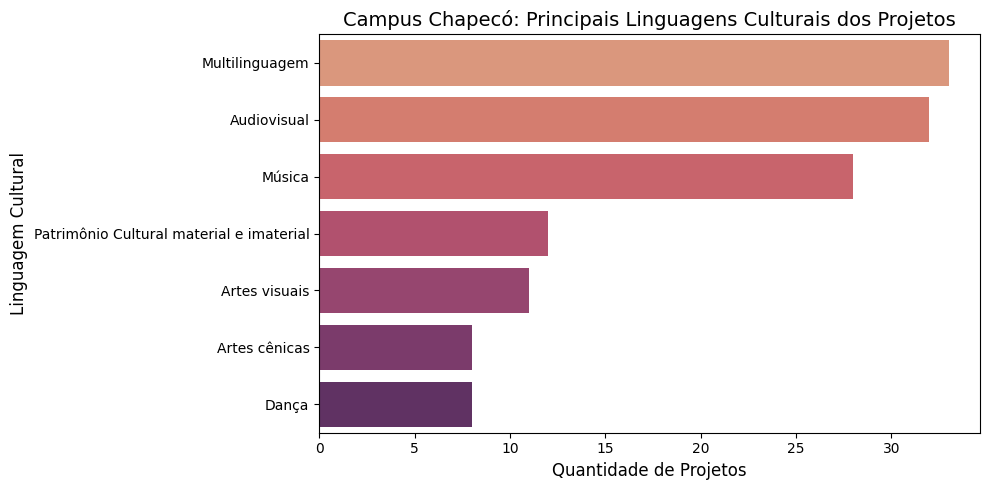

C:\Users\marco\AppData\Local\Temp\ipykernel_11872\1788981163.py:40: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=situacao_counts.values, y=situacao_counts.index, palette='viridis', ax=ax[1])


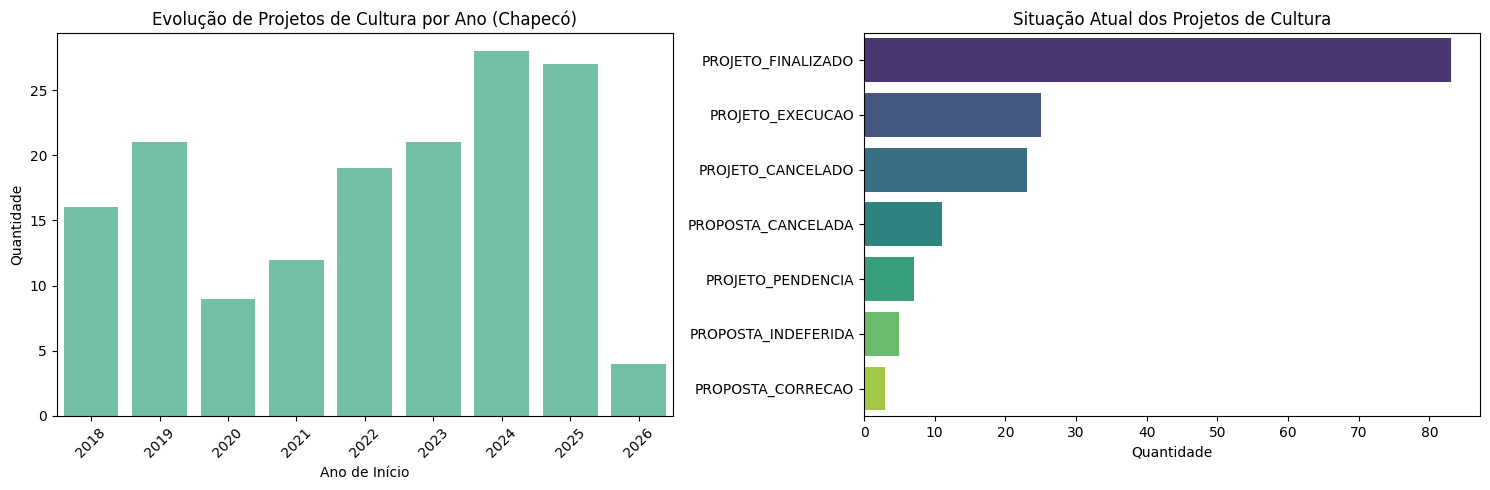

C:\Users\marco\AppData\Local\Temp\ipykernel_11872\1788981163.py:56: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=top_coordenadores.values, y=top_coordenadores.index, palette='mako')


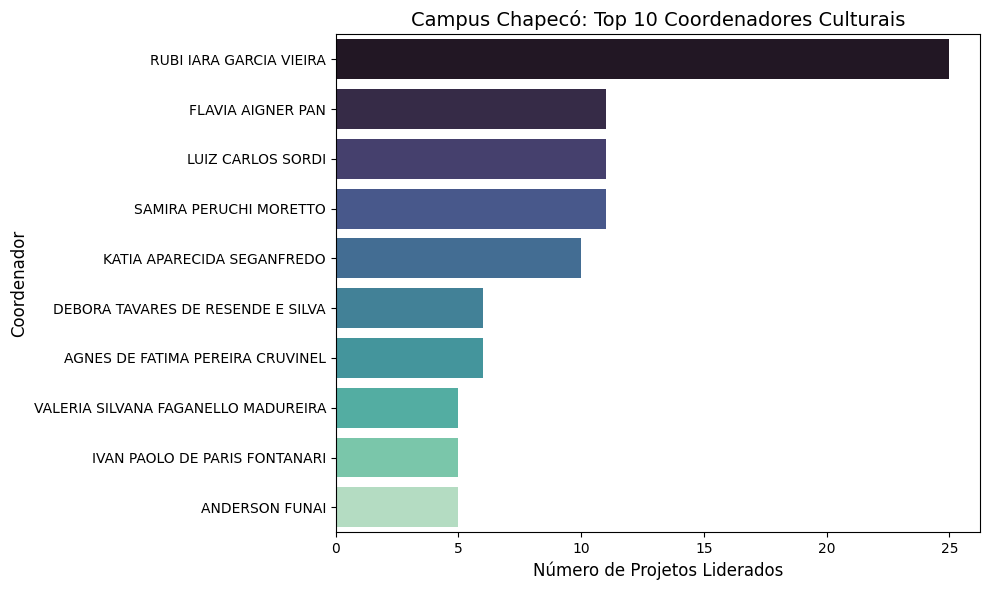

--- TOP 5 CURSOS DE CHAPECÓ MAIS ENVOLVIDOS EM CULTURA ---
nomes_cursos_envolvidos
ENFERMAGEM - INTEGRAL [CHAPECÓ]          43
MEDICINA - INTEGRAL [CHAPECÓ]            42
PEDAGOGIA - MATUTINO [CHAPECÓ]           28
CIÊNCIAS SOCIAIS - MATUTINO [CHAPECÓ]    24
PEDAGOGIA - NOTURNO [CHAPECÓ]            22
Name: count, dtype: int64


In [9]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# 0. A Mágica do Escopo (Filtrando apenas Chapecó)
df_cultura_chapeco = df_cultura[df_cultura['nome_campus'] == 'Chapecó'].copy()

# 1. Pré-processamento das datas
df_cultura_chapeco['data_inicio'] = pd.to_datetime(df_cultura_chapeco['data_inicio'], errors='coerce')
df_cultura_chapeco['data_fim'] = pd.to_datetime(df_cultura_chapeco['data_fim'], errors='coerce')
df_cultura_chapeco['ano_inicio'] = df_cultura_chapeco['data_inicio'].dt.year

# ---------------------------------------------------------
# ANÁLISE 1: O Perfil Artístico (Linguagens Culturais)
# ---------------------------------------------------------
plt.figure(figsize=(10, 5))
linguagem_counts = df_cultura_chapeco['linguagem'].value_counts()
sns.barplot(x=linguagem_counts.values, y=linguagem_counts.index, palette='flare')
plt.title('Campus Chapecó: Principais Linguagens Culturais dos Projetos', fontsize=14)
plt.xlabel('Quantidade de Projetos', fontsize=12)
plt.ylabel('Linguagem Cultural', fontsize=12)
plt.tight_layout()
plt.show()

# ---------------------------------------------------------
# ANÁLISE 2: Evolução no Tempo e Status
# ---------------------------------------------------------
fig, ax = plt.subplots(1, 2, figsize=(15, 5))

# Gráfico da esquerda: Crescimento
df_ano = df_cultura_chapeco[(df_cultura_chapeco['ano_inicio'] >= 2010) & (df_cultura_chapeco['ano_inicio'] <= 2026)]
sns.countplot(data=df_ano, x='ano_inicio', color='mediumaquamarine', ax=ax[0])
ax[0].set_title('Evolução de Projetos de Cultura por Ano (Chapecó)', fontsize=12)
ax[0].set_xlabel('Ano de Início')
ax[0].set_ylabel('Quantidade')
ax[0].tick_params(axis='x', rotation=45)

# Gráfico da direita: Situação Atual
situacao_counts = df_cultura_chapeco['situacao_projeto'].value_counts()
sns.barplot(x=situacao_counts.values, y=situacao_counts.index, palette='viridis', ax=ax[1])
ax[1].set_title('Situação Atual dos Projetos de Cultura', fontsize=12)
ax[1].set_xlabel('Quantidade')
ax[1].set_ylabel('')

plt.tight_layout()
plt.show()

# ---------------------------------------------------------
# ANÁLISE 3: Os "Produtores Culturais" (Top Coordenadores)
# ---------------------------------------------------------
# Separando os nomes caso haja mais de um coordenador por projeto
coord_series = df_cultura_chapeco['coordenadores'].dropna().str.split(';').explode().str.strip()
top_coordenadores = coord_series.value_counts().head(10)

plt.figure(figsize=(10, 6))
sns.barplot(x=top_coordenadores.values, y=top_coordenadores.index, palette='mako')
plt.title('Campus Chapecó: Top 10 Coordenadores Culturais', fontsize=14)
plt.xlabel('Número de Projetos Liderados', fontsize=12)
plt.ylabel('Coordenador', fontsize=12)
plt.tight_layout()
plt.show()

# ---------------------------------------------------------
# ANÁLISE BÔNUS: Integração de Cursos (Interdisciplinaridade)
# ---------------------------------------------------------
cursos_series = df_cultura_chapeco['nomes_cursos_envolvidos'].dropna().str.split(';').explode().str.strip()
top_cursos = cursos_series.value_counts().head(5)
print("--- TOP 5 CURSOS DE CHAPECÓ MAIS ENVOLVIDOS EM CULTURA ---")
print(top_cursos)